## 3. Feature Characteristics

Investigate the statistical properties of the input features, including their central tendency, variability and value ranges.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("../secom_data/raw")

data_path = DATA_DIR / "secom.data"
labels_path = DATA_DIR / "secom_labels.data"

X_raw = pd.read_csv(data_path, delimiter="\s+", header=None)
y_raw = pd.read_csv(labels_path, delimiter="\s+", header=None)

y = y_raw.iloc[:,0]

# Generate descriptive statistics for all input features
feature_stats = X_raw.describe().T

display(feature_stats.head(20))

# Calculate variance for each feature
feature_variance = X_raw.var()

# Sort features by variance (ascending)
variance_summary = feature_variance.sort_values()

# Display 20 features with the lowest variance
display(variance_summary.head(20))

constant_features = feature_variance[feature_variance == 0]

print("Number of constant features:", len(constant_features))
print("Constant feature indices:", constant_features.index.tolist())


,count,mean,std,min,25%,50%,75%,max
0,1561.0,3014.452896,73.621787,2743.2400,2966.260000,3011.49000,3056.650000,3356.3500
1,1560.0,2495.850231,80.407705,2158.7500,2452.247500,2499.40500,2538.822500,2846.4400
2,1553.0,2200.547318,29.513152,2060.6600,2181.044400,2201.06670,2218.055500,2315.2667
3,1553.0,1396.376627,441.691640,0.0000,1081.875800,1285.21440,1591.223500,3715.0417
4,1553.0,4.197013,56.355540,0.6815,1.017700,1.31680,1.525700,1114.5366
5,1553.0,100.000000,0.000000,100.0000,100.000000,100.00000,100.000000,100.0000
6,1553.0,101.112908,6.237214,82.1311,97.920000,101.51220,104.586700,129.2522
7,1558.0,0.121822,0.008961,0.0000,0.121100,0.12240,0.123800,0.1286
8,1565.0,1.462862,0.073897,1.1910,1.411200,1.46160,1.516900,1.6564
9,1565.0,-0.000841,0.015116,-0.0534,-0.010800,-0.00130,0.008400,0.0749


505    0.0
506    0.0
507    0.0
508    0.0
325    0.0
509    0.0
284    0.0
257    0.0
537    0.0
536    0.0
535    0.0
534    0.0
261    0.0
260    0.0
259    0.0
258    0.0
538    0.0
513    0.0
512    0.0
528    0.0
dtype: float64

Number of constant features: 116
Constant feature indices: [5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]
0       100.0
1       100.0
2       100.0
3       100.0
4       100.0
        ...  
1562    100.0
1563    100.0
1564    100.0
1565    100.0
1566    100.0
Name: 5, Length: 1567, dtype: float64


## Constant Features

- The variance analysis identified 116 constant features out of 590 features (approximately 19.66%). These features have zero variance, meaning their observed values do not vary across the available observations.

- Constant features are unlikely to provide useful information for distinguishing between passing and failing manufacturing outcomes. They may therefore be candidates for removal during preprocessing.

In [15]:
# Calculate minimum, maximum and range for each feature
feature_ranges = pd.DataFrame({
    "min": X_raw.min(),
    "max": X_raw.max(),
    "range": X_raw.max() - X_raw.min(),
    "std": X_raw.std()
})

# Sort features by range
feature_ranges = feature_ranges.sort_values(
    by="range",
    ascending=False
)

display(feature_ranges.head(20))

,min,max,range,std
161,0.0000,37943.0000,37943.0000,4239.245058
162,0.0000,36871.0000,36871.0000,6553.569317
24,-14804.5000,14106.0000,28910.5000,2902.690117
297,0.0000,18520.4683,18520.4683,3226.924298
296,0.0000,15559.9525,15559.9525,1975.111365
23,-9986.7500,2363.0000,12349.7500,1380.162148
140,0.0319,9998.8944,9998.8625,506.922106
204,0.0429,9998.4483,9998.4054,565.101239
159,0.0000,7791.0000,7791.0000,983.043021
67,0.4137,7272.8283,7272.4146,307.502293


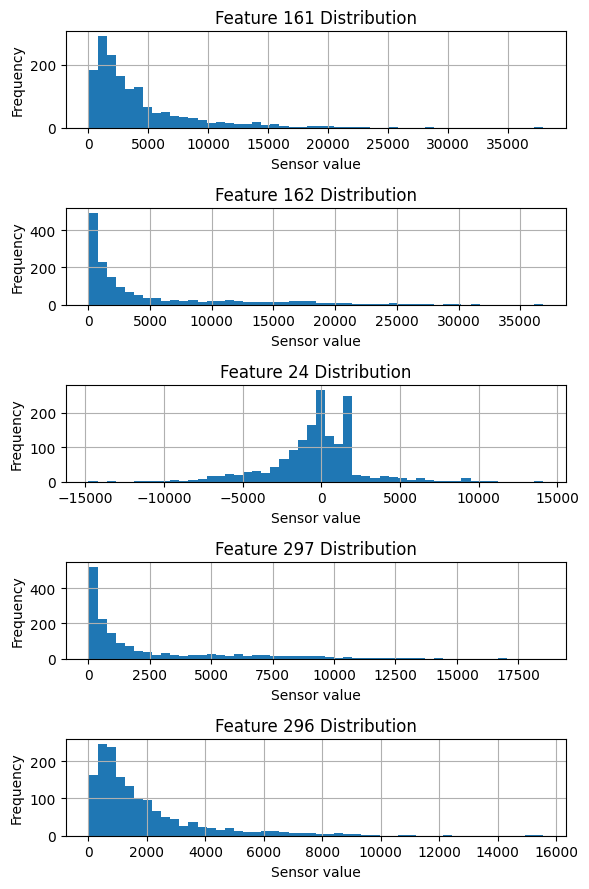

In [16]:
import matplotlib.pyplot as plt

# Select the five features with the largest ranges
top_features = feature_ranges.head(5).index

# Plot their distributions
fig, axes = plt.subplots(5, 1, figsize=(6, 9))

for feature, ax in zip(top_features, axes):
    X_raw[feature].hist(bins=50, ax=ax)
    ax.set_title(f"Feature {feature} Distribution")
    ax.set_xlabel("Sensor value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()